# Amazon UK Product Listings: Univariate EDA

This notebook explores listing frequency, prices, and customer ratings from the Amazon UK product dataset. The analysis combines descriptive statistics and visualisations with business-focused conclusions about assortment, pricing, and customer sentiment.

**Setup:** download the CSV from the [Kaggle dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/) and place it in this directory before running the notebook.

## Part 1 — Product categories

Listing frequency is a useful proxy for the breadth of assortment and the categories receiving the most seller attention.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [5]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [6]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [7]:
category_frequency = df["category"].value_counts()

category_frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [8]:
top_5_categories = df["category"].value_counts().head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [9]:
top_category_percentage = (
    df["category"].value_counts().iloc[0] / len(df) * 100
)

print(f"Sports & Outdoors represents {top_category_percentage:.2f}% of all listings.")

Sports & Outdoors represents 34.22% of all listings.


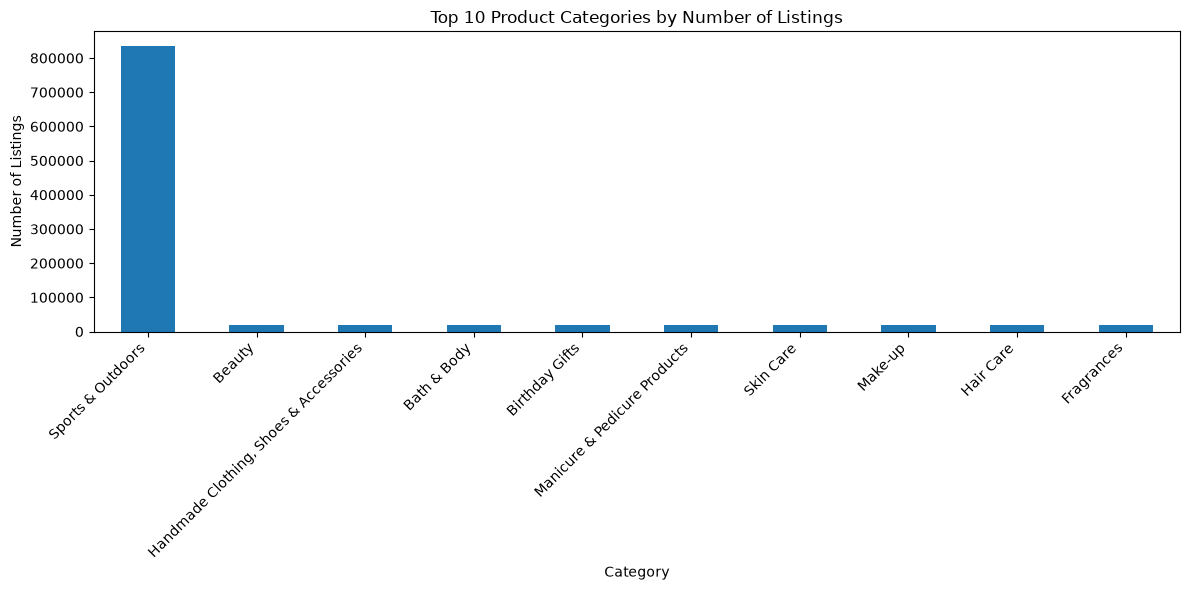

In [10]:
import matplotlib.pyplot as plt

top_10_categories = df["category"].value_counts().head(10)

plt.figure(figsize=(12, 6))

top_10_categories.plot(kind="bar")

plt.title("Top 10 Product Categories by Number of Listings")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

,listing_count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
Manicure & Pedicure Products,18940
Skin Care,18769
Make-up,18756
Hair Care,18735


Top 5 categories:


,listing_count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


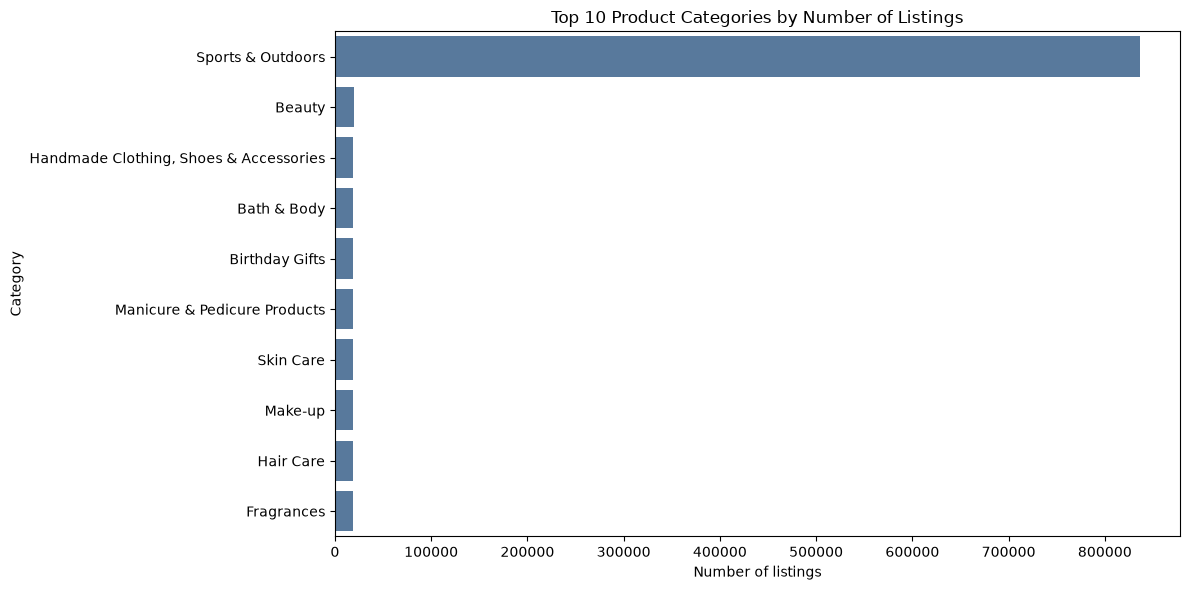

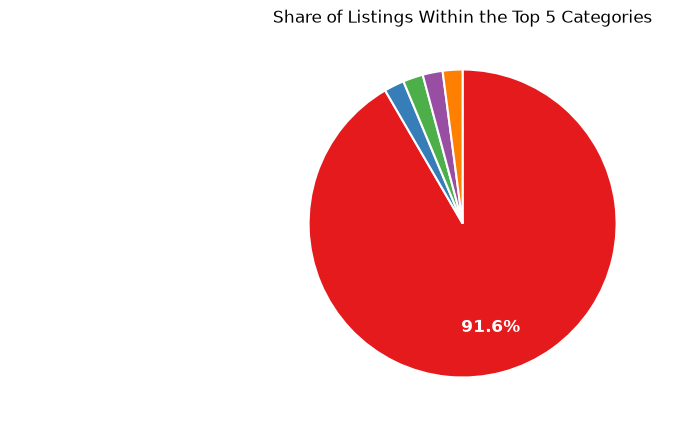

The five largest categories account for 37.4% of all listings; the largest category accounts for 34.2%.


In [12]:
category_frequency = df["category"].value_counts(dropna=False)
top_5_categories = category_frequency.head(5)
top_10_categories = category_frequency.head(10)

display(category_frequency.to_frame("listing_count").head(20))
print("Top 5 categories:")
display(top_5_categories.to_frame("listing_count"))

plt.figure(figsize=(12, 6))
sns.barplot(x=top_10_categories.values, y=top_10_categories.index, color="#4C78A8")
plt.title("Top 10 Product Categories by Number of Listings")
plt.xlabel("Number of listings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.pie(
    top_5_categories.values,
    labels=top_5_categories.index,
    startangle=90,
    counterclock=False,
    colors=sns.color_palette('Set1'),
    autopct=lambda p: f'{p:.1f}%' if p >= 5 else '',  # skip the slices too thin to hold text
    pctdistance=0.7,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'color': 'white', 'fontsize': 12, 'fontweight': 'bold'}
    )
plt.title("Share of Listings Within the Top 5 Categories")
plt.show()

top_5_share = top_5_categories.sum() / category_frequency.sum()
top_category_share = top_5_categories.iloc[0] / category_frequency.sum()
print(
    f"The five largest categories account for {top_5_share:.1%} of all listings; "
    f"the largest category accounts for {top_category_share:.1%}."
)

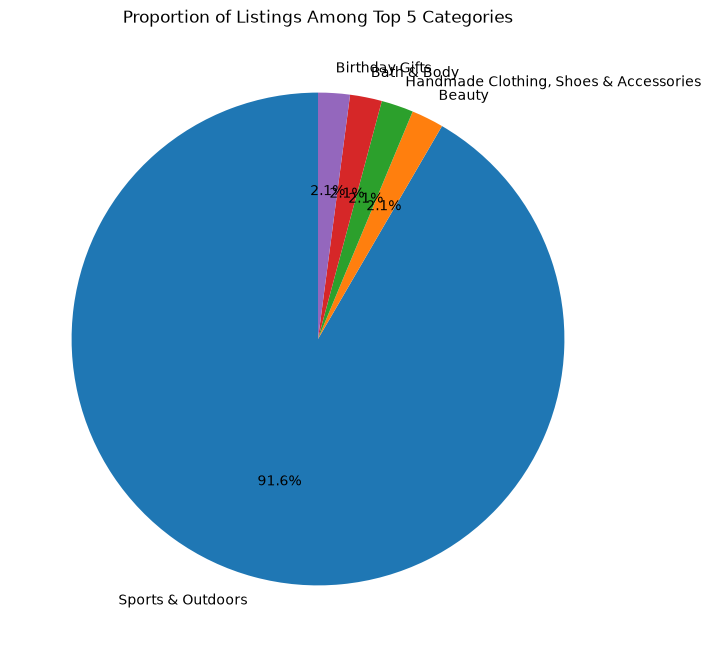

In [11]:
top_5_categories = df["category"].value_counts().head(5)

plt.figure(figsize=(8, 8))

plt.pie(
    top_5_categories,
    labels=top_5_categories.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Proportion of Listings Among Top 5 Categories")

plt.show()

**Business interpretation:** Categories with the highest listing counts represent the most crowded competitive spaces. A dominant category may offer strong demand, but it can also require sharper differentiation and inventory planning. Smaller categories may provide opportunities for focused assortment expansion.

## Part 2 — Product pricing

Prices are analysed after coercion to numeric values. Missing prices are excluded from numeric summaries and plots.

In [13]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()

print(f"Mean: £{mean_price:.2f}")
print(f"Median: £{median_price:.2f}")
print(f"Mode: £{mode_price.iloc[0]:.2f}")

Mean: £89.24
Median: £19.09
Mode: £9.99


In [14]:
price_variance = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min()

price_q1 = df["price"].quantile(0.25)
price_q3 = df["price"].quantile(0.75)
price_iqr = price_q3 - price_q1

print(f"Variance: {price_variance:.2f}")
print(f"Standard deviation: £{price_std:.2f}")
print(f"Range: £{price_range:.2f}")
print(f"IQR: £{price_iqr:.2f}")

Variance: 119445.49
Standard deviation: £345.61
Range: £100000.00
IQR: £36.00


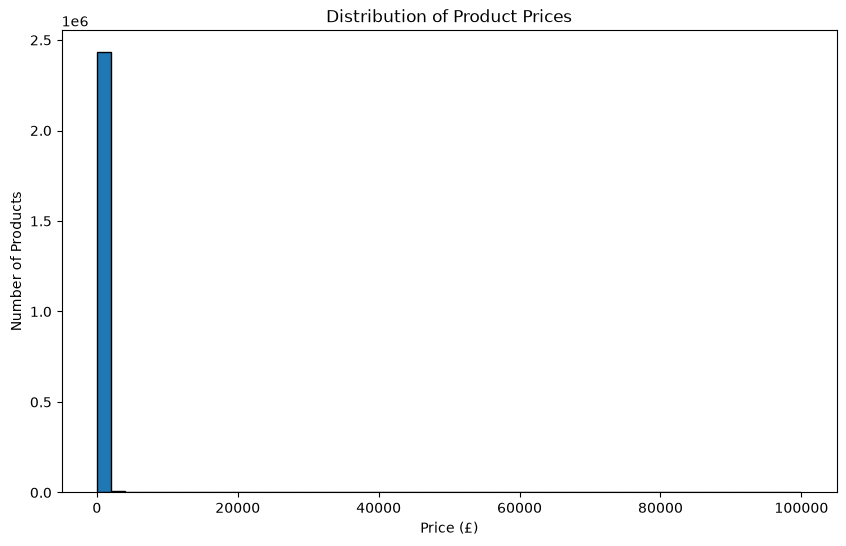

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(df["price"], bins=50, edgecolor="black")

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.show()

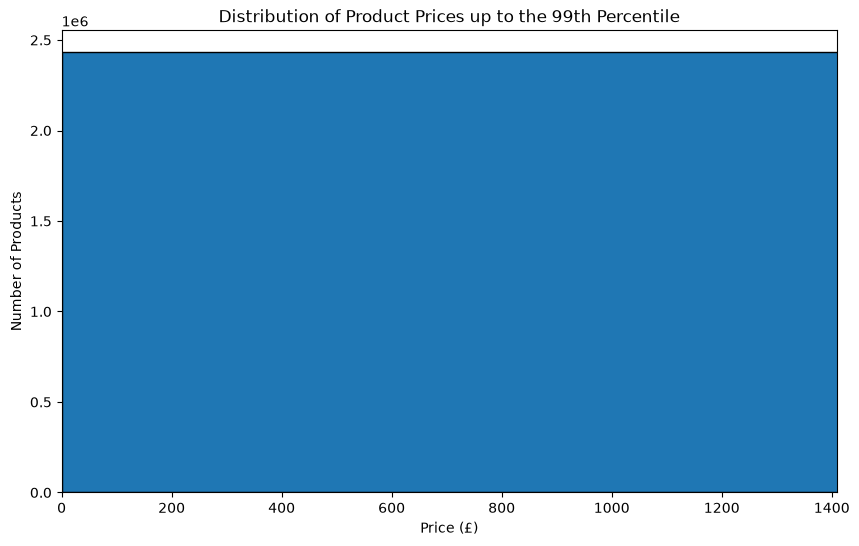

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(df["price"], bins=50, edgecolor="black")

plt.xlim(0, df["price"].quantile(0.99))

plt.title("Distribution of Product Prices up to the 99th Percentile")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.show()

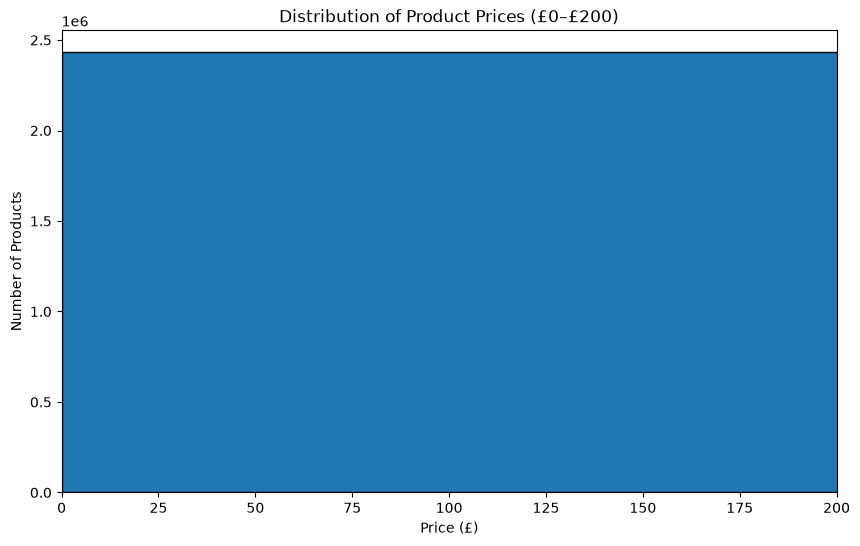

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(df["price"], bins=50, edgecolor="black")

plt.xlim(0, 200)

plt.title("Distribution of Product Prices (£0–£200)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.show()

/var/folders/z0/p0sbgv550gd8xrw6rnrn1b9m0000gn/T/ipykernel_7042/3304125668.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["price"], vert=False)


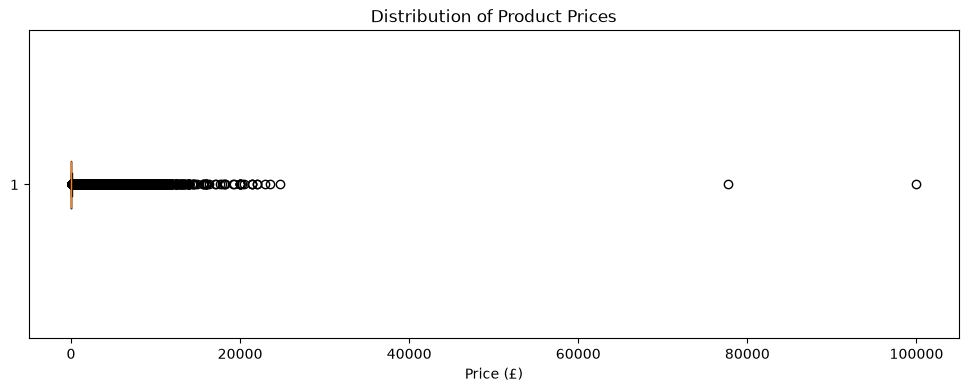

In [18]:
plt.figure(figsize=(12, 4))

plt.boxplot(df["price"], vert=False)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")

plt.show()

/var/folders/z0/p0sbgv550gd8xrw6rnrn1b9m0000gn/T/ipykernel_7042/193273607.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


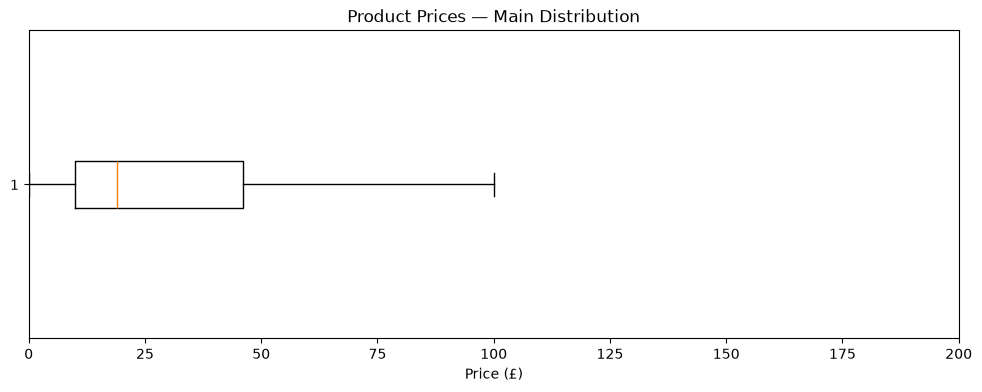

In [19]:
plt.figure(figsize=(12, 4))

plt.boxplot(
    df["price"],
    vert=False,
    showfliers=False
)

plt.xlim(0, 200)

plt.title("Product Prices — Main Distribution")
plt.xlabel("Price (£)")

plt.show()

/var/folders/z0/p0sbgv550gd8xrw6rnrn1b9m0000gn/T/ipykernel_7042/3304125668.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["price"], vert=False)


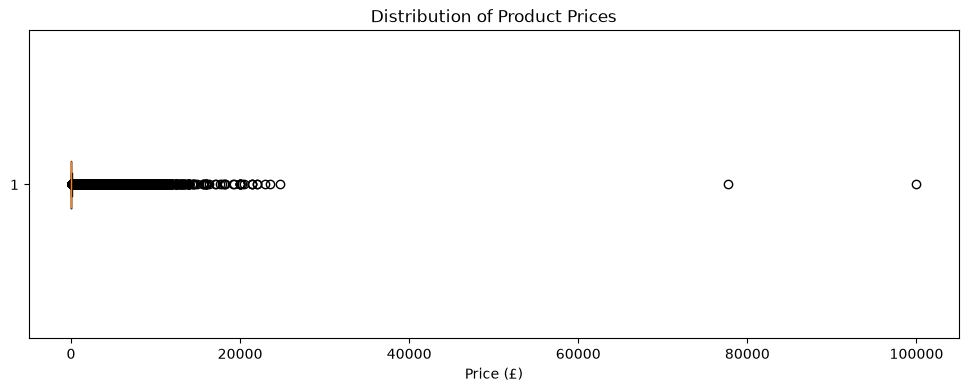

In [20]:
plt.figure(figsize=(12, 4))

plt.boxplot(df["price"], vert=False)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")

plt.show()

In [21]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()

print(f"Mean: {mean_rating:.2f}")
print(f"Median: {median_rating:.2f}")
print(f"Mode: {mode_rating.iloc[0]:.2f}")

Mean: 2.15
Median: 0.00
Mode: 0.00


In [22]:
(df["stars"] == 0).sum()

np.int64(1225641)

In [23]:
(df["stars"] == 0).mean() * 100

np.float64(50.15613931776674)

In [24]:
ratings_available = df[df["stars"] > 0]["stars"]

In [25]:
print(f"Mean: {ratings_available.mean():.2f}")
print(f"Median: {ratings_available.median():.2f}")
print(f"Mode: {ratings_available.mode().iloc[0]:.2f}")

Mean: 4.32
Median: 4.40
Mode: 4.50


In [26]:
rating_variance = df["stars"].var()
rating_std = df["stars"].std()

rating_q1 = df["stars"].quantile(0.25)
rating_q3 = df["stars"].quantile(0.75)

rating_iqr = rating_q3 - rating_q1

print(f"Variance: {rating_variance:.4f}")
print(f"Standard deviation: {rating_std:.4f}")
print(f"IQR: {rating_iqr:.4f}")

Variance: 4.8174
Standard deviation: 2.1949
IQR: 4.4000


In [27]:
# Including zero values
print("Including zeros")
print("Mean:", df["stars"].mean())
print("Median:", df["stars"].median())
print("Std:", df["stars"].std())
print("IQR:", df["stars"].quantile(0.75) - df["stars"].quantile(0.25))

# Excluding zero values
ratings_available = df.loc[df["stars"] > 0, "stars"]

print("\nExcluding zeros")
print("Mean:", ratings_available.mean())
print("Median:", ratings_available.median())
print("Std:", ratings_available.std())
print("IQR:", ratings_available.quantile(0.75) - ratings_available.quantile(0.25))

Including zeros
Mean: 2.152836472966066
Median: 0.0
Std: 2.194865378513421
IQR: 4.4

Excluding zeros
Mean: 4.319160762226911
Median: 4.4
Std: 0.5552867504620729
IQR: 0.5


In [28]:
rating_skewness = df["stars"].skew()
rating_kurtosis = df["stars"].kurt()

print(f"Skewness: {rating_skewness:.4f}")
print(f"Kurtosis: {rating_kurtosis:.4f}")

Skewness: 0.0812
Kurtosis: -1.9260


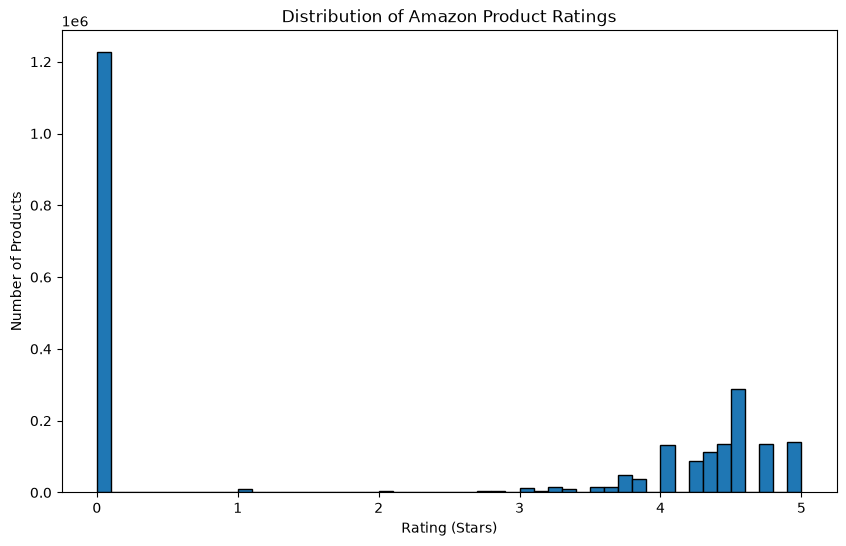

In [29]:
plt.figure(figsize=(10, 6))

plt.hist(df["stars"], bins=50, edgecolor="black")

plt.title("Distribution of Amazon Product Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")

plt.show()

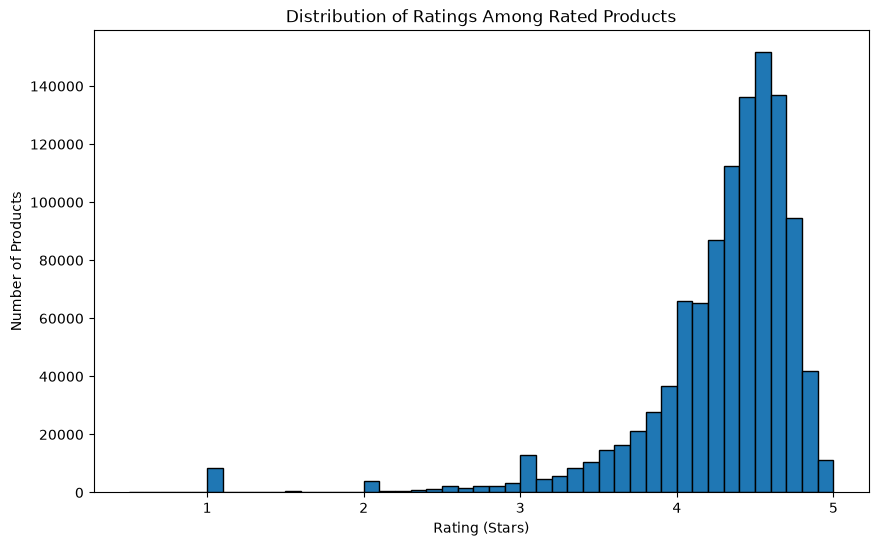

In [30]:
plt.figure(figsize=(10, 6))

plt.hist(
    ratings_available,
    bins=np.arange(0.5, 5.1, 0.1),
    edgecolor="black"
)

plt.title("Distribution of Ratings Among Rated Products")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")

plt.show()

/var/folders/z0/p0sbgv550gd8xrw6rnrn1b9m0000gn/T/ipykernel_7042/193273607.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


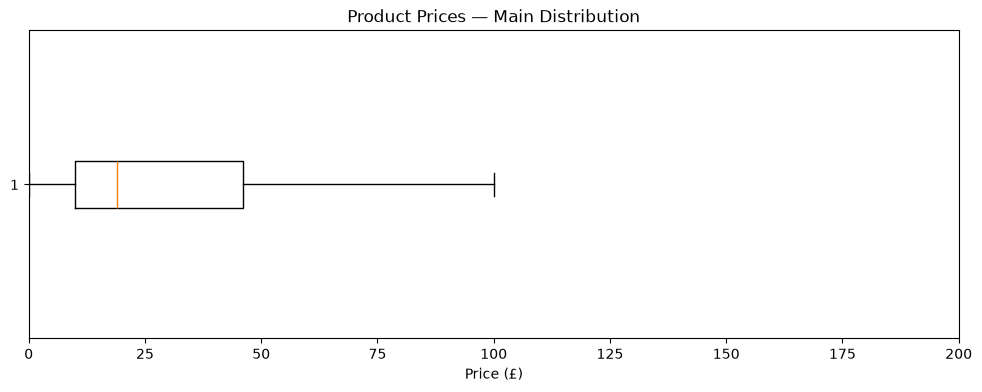

In [31]:
plt.figure(figsize=(12, 4))

plt.boxplot(
    df["price"],
    vert=False,
    showfliers=False
)

plt.xlim(0, 200)

plt.title("Product Prices — Main Distribution")
plt.xlabel("Price (£)")

plt.show()

## Part 3 — Product ratings

Ratings are summarised with central tendency, dispersion, skewness, and kurtosis to assess customer sentiment and the shape of the distribution.

In [32]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()

print(f"Mean: {mean_rating:.2f}")
print(f"Median: {median_rating:.2f}")
print(f"Mode: {mode_rating.iloc[0]:.2f}")

Mean: 2.15
Median: 0.00
Mode: 0.00


In [33]:
(df["stars"] == 0).sum()

np.int64(1225641)

In [34]:
(df["stars"] == 0).mean() * 100

np.float64(50.15613931776674)

In [35]:
ratings_available = df[df["stars"] > 0]["stars"]

In [36]:
print(f"Mean: {ratings_available.mean():.2f}")
print(f"Median: {ratings_available.median():.2f}")
print(f"Mode: {ratings_available.mode().iloc[0]:.2f}")

Mean: 4.32
Median: 4.40
Mode: 4.50


In [37]:
rating_variance = df["stars"].var()
rating_std = df["stars"].std()

rating_q1 = df["stars"].quantile(0.25)
rating_q3 = df["stars"].quantile(0.75)

rating_iqr = rating_q3 - rating_q1

print(f"Variance: {rating_variance:.4f}")
print(f"Standard deviation: {rating_std:.4f}")
print(f"IQR: {rating_iqr:.4f}")

Variance: 4.8174
Standard deviation: 2.1949
IQR: 4.4000


In [38]:
# Including zero values
print("Including zeros")
print("Mean:", df["stars"].mean())
print("Median:", df["stars"].median())
print("Std:", df["stars"].std())
print("IQR:", df["stars"].quantile(0.75) - df["stars"].quantile(0.25))

# Excluding zero values
ratings_available = df.loc[df["stars"] > 0, "stars"]

print("\nExcluding zeros")
print("Mean:", ratings_available.mean())
print("Median:", ratings_available.median())
print("Std:", ratings_available.std())
print("IQR:", ratings_available.quantile(0.75) - ratings_available.quantile(0.25))

Including zeros
Mean: 2.152836472966066
Median: 0.0
Std: 2.194865378513421
IQR: 4.4

Excluding zeros
Mean: 4.319160762226911
Median: 4.4
Std: 0.5552867504620729
IQR: 0.5


In [39]:
rating_skewness = df["stars"].skew()
rating_kurtosis = df["stars"].kurt()

print(f"Skewness: {rating_skewness:.4f}")
print(f"Kurtosis: {rating_kurtosis:.4f}")

Skewness: 0.0812
Kurtosis: -1.9260


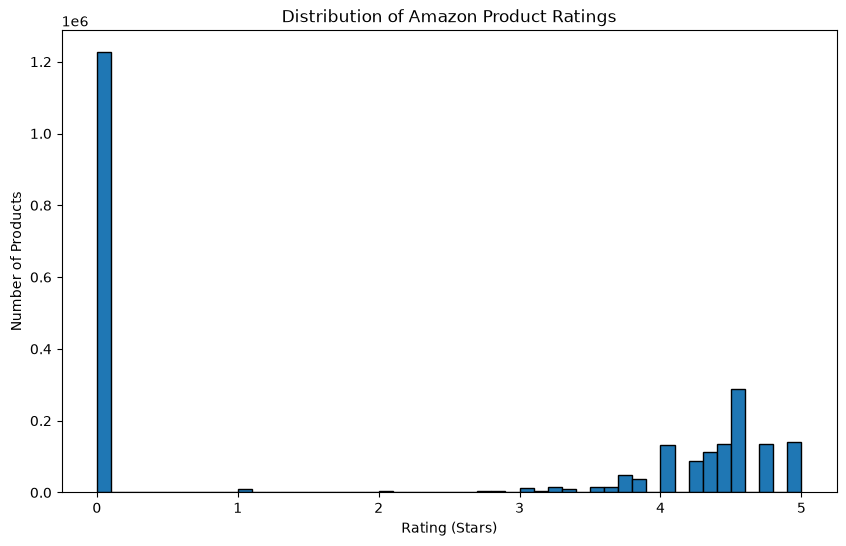

In [40]:
plt.figure(figsize=(10, 6))

plt.hist(df["stars"], bins=50, edgecolor="black")

plt.title("Distribution of Amazon Product Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")

plt.show()

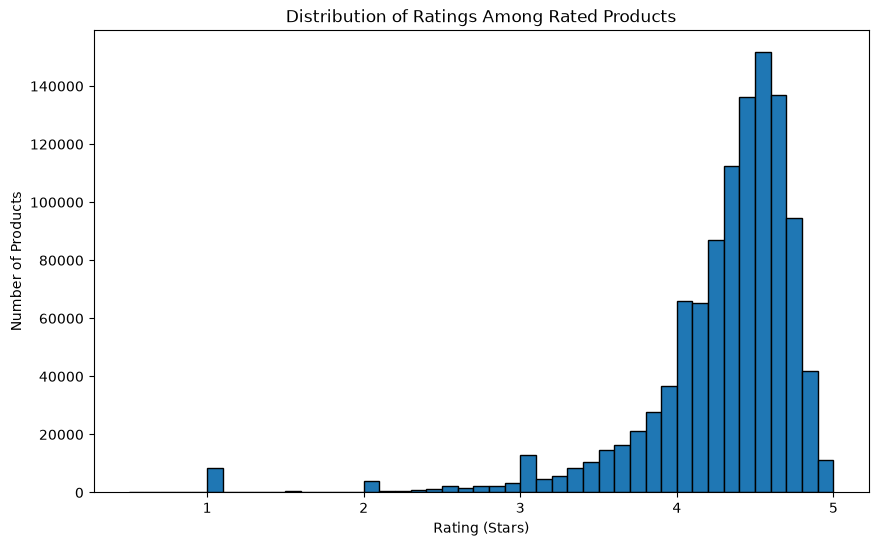

In [41]:
plt.figure(figsize=(10, 6))

plt.hist(
    ratings_available,
    bins=np.arange(0.5, 5.1, 0.1),
    edgecolor="black"
)

plt.title("Distribution of Ratings Among Rated Products")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")

plt.show()

**Business interpretation:** A high median rating with a narrow IQR suggests consistently positive customer sentiment. Positive skew indicates more observations at the lower end with a tail toward higher ratings, while negative skew indicates concentration at higher ratings with a tail toward lower ratings. Kurtosis describes whether ratings are more concentrated around the centre or have heavier tails than a normal distribution.

## Executive summary

- **Assortment:** Use the top-category table and concentration percentages to identify crowded categories and possible assortment gaps.
- **Pricing:** Use the median and IQR for typical pricing decisions; review high-price outliers separately rather than allowing them to distort the average.
- **Customer sentiment:** Use the median, IQR, skewness, and rating histogram to assess whether customer feedback is broadly positive and consistent.
- **Data quality:** Missing values and non-numeric values are surfaced before analysis, so conclusions should be qualified if coverage is incomplete.